# `SensorSearch` and xarray demo

This notebook demonstrates the format-independent `SensorSearch` class from `sensor_names`. It first uses a small metadata table, then opens the bundled NetCDF files as xarray datasets and uses search results to select sensors.

Search text is case-insensitive and spaces are ignored. Different filters are combined with AND; multiple values within one filter are combined with OR.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

try:
    from wetb.hawc2.sensor_names import SensorSearch
except ModuleNotFoundError:
    # Source-tree fallback when the installed wetb package is older.
    import sys
    workspace = Path.cwd()
    if not (workspace / "hawc2" / "sensor_names.py").exists():
        workspace = Path.cwd() / ".." / ".."
    sys.path.insert(0, str(workspace.resolve()))
    from hawc2.sensor_names import SensorSearch

## Construct a search directly from metadata

In [2]:
search = SensorSearch(
    names=["Time", "Tower base Mx", "Tower base My", "Blade root My", "Rotor speed"],
    units=["s", "kNm", "kNm", "kNm", "rpm"],
    desc=["Time", "Tower base load #tbmx", "Tower base load #tbmy",
          "Blade 1 root load #brmy", "Shaft speed #omega"],
    htc=["time", "mbdy moment tower #tbmx", "mbdy moment tower #tbmy",
         "mbdy moment blade1 #brmy", "bearing angle_speed shaft_rot #omega"],
    channel_ids=[0, 1, 2, 3, 4],
)
search()

,Channel_id,Name,Unit,Description,HTC_input
0,0,Time,s,Time,time
1,1,Tower base Mx,kNm,Tower base load #tbmx,mbdy moment tower #tbmx
2,2,Tower base My,kNm,Tower base load #tbmy,mbdy moment tower #tbmy
3,3,Blade root My,kNm,Blade 1 root load #brmy,mbdy moment blade1 #brmy
4,4,Rotor speed,rpm,Shaft speed #omega,bearing angle_speed shaft_rot #omega


## Filter sensor metadata

Every call returns a pandas DataFrame. No time-series data is loaded by `SensorSearch`.

In [3]:
display(search(name="tower"))
display(search(name="TOWER BASE", unit="knm"))
display(search(desc=["blade 1", "shaft speed"]))
display(search(htc="mbdy moment", label=["tbmx", "tbmy"]))

,Channel_id,Name,Unit,Description,HTC_input
0,1,Tower base Mx,kNm,Tower base load #tbmx,mbdy moment tower #tbmx
1,2,Tower base My,kNm,Tower base load #tbmy,mbdy moment tower #tbmy


,Channel_id,Name,Unit,Description,HTC_input
0,1,Tower base Mx,kNm,Tower base load #tbmx,mbdy moment tower #tbmx
1,2,Tower base My,kNm,Tower base load #tbmy,mbdy moment tower #tbmy


,Channel_id,Name,Unit,Description,HTC_input
0,3,Blade root My,kNm,Blade 1 root load #brmy,mbdy moment blade1 #brmy
1,4,Rotor speed,rpm,Shaft speed #omega,bearing angle_speed shaft_rot #omega


,Channel_id,Name,Unit,Description,HTC_input
0,1,Tower base Mx,kNm,Tower base load #tbmx,mbdy moment tower #tbmx
1,2,Tower base My,kNm,Tower base load #tbmy,mbdy moment tower #tbmy


Channel IDs can be returned directly, or used to retrieve metadata in a requested order.

In [4]:
tower_ids = search.get_sensor_id(name="tower", unit="kNm")
print("Tower channel IDs:", tower_ids)
search.by_channel_ids([4, 1, 3])

Tower channel IDs: [1 2]


,Channel_id,Name,Unit,Description,HTC_input
0,4,Rotor speed,rpm,Shaft speed #omega,bearing angle_speed shaft_rot #omega
1,1,Tower base Mx,kNm,Tower base load #tbmx,mbdy moment tower #tbmx
2,3,Blade root My,kNm,Blade 1 root load #brmy,mbdy moment blade1 #brmy


## Other constructors

`SensorSearch` can also be created from the traditional HAWC2 `ChInfo` structure or a metadata DataFrame.

In [5]:
chinfo = [
    search.df["Name"].tolist(),
    search.df["Unit"].tolist(),
    search.df["Description"].tolist(),
    search.df["HTC_input"].tolist(),
]
from_chinfo = SensorSearch.from_chinfo(chinfo)
from_dataframe = SensorSearch.from_dataframe(search.df)
display(from_chinfo(name="rotor"))
display(from_dataframe(label="brmy"))

,Channel_id,Name,Unit,Description,HTC_input
0,4,Rotor speed,rpm,Shaft speed #omega,bearing angle_speed shaft_rot #omega


,Channel_id,Name,Unit,Description,HTC_input
0,3,Blade root My,kNm,Blade 1 root load #brmy,mbdy moment blade1 #brmy


## Open the NetCDF files as xarray datasets

`xarray.open_dataset` reads a `.nc` file into an `xarray.Dataset`. The helper below works whether Jupyter starts in this directory or at the repository root.

In [6]:
demo_dir = Path('.')
if not (demo_dir / "statistics.nc").exists():
    demo_dir = Path("hawc2/hawc2io_demo")

statistics_raw = xr.open_dataset(demo_dir / "statistics.nc")
equivalent_loads_raw = xr.open_dataset(demo_dir / "equivalent_loads.nc")
display(statistics_raw)
display(equivalent_loads_raw)

<xarray.Dataset> Size: 38MB
Dimensions:             (filename: 1580, sensor_name: 758, statistic: 4)
Coordinates:
  * filename            (filename) object 13kB 'DLC12/DLC12_wsp03_wdir000_s10...
  * sensor_name         (sensor_name) object 6kB 'bea1 angle' ... 'DLL inp   ...
  * statistic           (statistic) object 32B 'min' 'mean' 'max' 'std'
    sensor_description  (sensor_name) object 6kB ...
    sensor_unit         (sensor_name) object 6kB ...
Data variables:
    statistics          (filename, sensor_name, statistic) float64 38MB ...

<xarray.Dataset> Size: 58MB
Dimensions:             (filename: 1580, sensor_name: 758, m: 6)
Coordinates:
  * filename            (filename) object 13kB 'DLC12/DLC12_wsp03_wdir000_s10...
  * sensor_name         (sensor_name) object 6kB 'bea1 angle' ... 'DLL inp   ...
  * m                   (m) float64 48B 3.0 4.0 6.0 8.0 10.0 12.0
    sensor_description  (sensor_name) object 6kB ...
    sensor_unit         (sensor_name) object 6kB ...
Data variables:
    equivalent_loads    (filename, sensor_name, m) float64 57MB ...

The files use `sensor_name` as both the dimension and the name coordinate. The next function converts that layout to an integer `sensor` dimension and keeps the names as a separate coordinate. This is the layout expected by `SensorSearch.from_xarray` when numeric channel IDs are desired.

In [7]:
def normalize_sensor_coordinates(ds):
    sensor_names = ds["sensor_name"].values.copy()
    ds = ds.rename({"sensor_name": "sensor"})
    return ds.assign_coords(
        sensor=np.arange(ds.sizes["sensor"]),
        sensor_name=("sensor", sensor_names),
    )

statistics = normalize_sensor_coordinates(statistics_raw)
equivalent_loads = normalize_sensor_coordinates(equivalent_loads_raw)
statistics

<xarray.Dataset> Size: 38MB
Dimensions:             (filename: 1580, sensor: 758, statistic: 4)
Coordinates:
  * filename            (filename) object 13kB 'DLC12/DLC12_wsp03_wdir000_s10...
  * sensor              (sensor) int32 3kB 0 1 2 3 4 5 ... 753 754 755 756 757
  * statistic           (statistic) object 32B 'min' 'mean' 'max' 'std'
    sensor_description  (sensor) object 6kB ...
    sensor_unit         (sensor) object 6kB ...
    sensor_name         (sensor) object 6kB 'bea1 angle' ... 'DLL inp   5:   1'
Data variables:
    statistics          (filename, sensor, statistic) float64 38MB ...

## Build `SensorSearch` from xarray

In [8]:
statistics_search = SensorSearch.from_xarray(statistics["statistics"])
load_search = SensorSearch.from_xarray(equivalent_loads["equivalent_loads"])
statistics_search().head(10)

,Channel_id,Name,Unit,Description
0,0,bea1 angle,deg,shaft_rot angle
1,1,bea1 angle_speed,rpm,shaft_rot angle speed
2,2,bea2 angle,deg,pitch1 angle
3,3,bea2 angle_speed,deg/s,pitch1 angle speed
4,4,bea2 angle,deg,pitch2 angle
5,5,bea2 angle_speed,deg/s,pitch2 angle speed
6,6,bea2 angle,deg,pitch3 angle
7,7,bea2 angle_speed,deg/s,pitch3 angle speed
8,8,Omega,rad/s,Rotor speed
9,9,Ae rot. torque,kNm,Aero rotor torque


Search for sensors first, then pass their numeric IDs to xarray's `isel`. The metadata table and selected data remain easy to inspect independently.

In [9]:
moment_metadata = statistics_search(desc="moment", unit="knm")
display(moment_metadata.head(10))

moment_ids = moment_metadata["Channel_id"].tolist()
selected_statistics = statistics["statistics"].isel(sensor=moment_ids)
selected_statistics

,Channel_id,Name,Unit,Description
0,18,Mx coo: local,kNm,MomentMx Mbdy:tower nodenr: 1 coo: local to...
1,19,My coo: local,kNm,MomentMy Mbdy:tower nodenr: 1 coo: local to...
2,20,Mz coo: local,kNm,MomentMz Mbdy:tower nodenr: 1 coo: local to...
3,24,Mx coo: local,kNm,MomentMx Mbdy:tower nodenr: 2 coo: local to...
4,25,My coo: local,kNm,MomentMy Mbdy:tower nodenr: 2 coo: local to...
5,26,Mz coo: local,kNm,MomentMz Mbdy:tower nodenr: 2 coo: local to...
6,30,Mx coo: local,kNm,MomentMx Mbdy:tower nodenr: 3 coo: local to...
7,31,My coo: local,kNm,MomentMy Mbdy:tower nodenr: 3 coo: local to...
8,32,Mz coo: local,kNm,MomentMz Mbdy:tower nodenr: 3 coo: local to...
9,36,Mx coo: local,kNm,MomentMx Mbdy:tower nodenr: 4 coo: local to...


<xarray.DataArray 'statistics' (filename: 1580, sensor: 339, statistic: 4)> Size: 17MB
[2142480 values with dtype=float64]
Coordinates:
  * filename            (filename) object 13kB 'DLC12/DLC12_wsp03_wdir000_s10...
  * sensor              (sensor) int32 1kB 18 19 20 24 25 ... 686 690 691 692
  * statistic           (statistic) object 32B 'min' 'mean' 'max' 'std'
    sensor_description  (sensor) object 3kB 'MomentMx Mbdy:tower nodenr:   1 ...
    sensor_unit         (sensor) object 3kB 'kNm' 'kNm' 'kNm' ... 'kNm' 'kNm'
    sensor_name         (sensor) object 3kB 'Mx coo: local' ... 'Mz coo: local'

The same pattern selects fatigue-equivalent loads. Here the query finds blade-root sensors and selects the first simulation file for a compact result.

In [10]:
blade_metadata = load_search(desc="blade", unit="knm")
display(blade_metadata.head(10))

blade_ids = blade_metadata["Channel_id"].tolist()
blade_loads = equivalent_loads["equivalent_loads"].isel(
    filename=0, sensor=blade_ids[:8]
)
blade_loads

,Channel_id,Name,Unit,Description
0,84,Mx coo: local,kNm,MomentMx Mbdy:blade1 nodenr: 1 coo: local b...
1,85,My coo: local,kNm,MomentMy Mbdy:blade1 nodenr: 1 coo: local b...
2,86,Mz coo: local,kNm,MomentMz Mbdy:blade1 nodenr: 1 coo: local b...
3,90,Mx coo: local,kNm,MomentMx Mbdy:blade1 nodenr: 2 coo: local b...
4,91,My coo: local,kNm,MomentMy Mbdy:blade1 nodenr: 2 coo: local b...
5,92,Mz coo: local,kNm,MomentMz Mbdy:blade1 nodenr: 2 coo: local b...
6,96,Mx coo: local,kNm,MomentMx Mbdy:blade1 nodenr: 3 coo: local b...
7,97,My coo: local,kNm,MomentMy Mbdy:blade1 nodenr: 3 coo: local b...
8,98,Mz coo: local,kNm,MomentMz Mbdy:blade1 nodenr: 3 coo: local b...
9,102,Mx coo: local,kNm,MomentMx Mbdy:blade1 nodenr: 4 coo: local b...


<xarray.DataArray 'equivalent_loads' (sensor: 8, m: 6)> Size: 384B
[48 values with dtype=float64]
Coordinates:
  * sensor              (sensor) int32 32B 84 85 86 90 91 92 96 97
  * m                   (m) float64 48B 3.0 4.0 6.0 8.0 10.0 12.0
    filename            <U36 144B 'DLC12/DLC12_wsp03_wdir000_s1001.hdf5'
    sensor_description  (sensor) object 64B 'MomentMx Mbdy:blade1 nodenr:   1...
    sensor_unit         (sensor) object 64B 'kNm' 'kNm' 'kNm' ... 'kNm' 'kNm'
    sensor_name         (sensor) object 64B 'Mx coo: local' ... 'My coo: local'

## Plot a searched selection

KeyError: "no index found for coordinate 'sensor_name'"

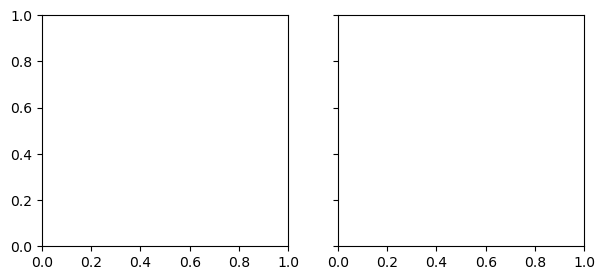

In [11]:
plot_metadata = statistics_search(desc="shaft_rot")
plot_ids = plot_metadata["Channel_id"].tolist()[:4]
plot_data = statistics["statistics"].isel(filename=0, sensor=plot_ids)
plot_data.plot(x="statistic", col="sensor_name", col_wrap=2, marker="o")
plt.suptitle("Shaft statistics selected with SensorSearch", y=1.03)

## Empty results and HTC metadata

A query with no matches returns an empty DataFrame. These NetCDF files do not contain `HTC_input`, so an HTC query raises a clear error instead of silently returning no sensors.

In [12]:
empty = statistics_search(name="sensor that does not exist")
print("Empty result:", empty.shape)

try:
    statistics_search(htc="output")
except ValueError as error:
    print(error)

Empty result: (0, 4)
HTC_input metadata is not available


## Close file handles

Datasets opened lazily should be closed when the notebook is finished with them.

In [ ]:
statistics_raw.close()
equivalent_loads_raw.close()